In [1]:
import os
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/Leangonplu/Ecommerce_Customer_Churn_Analysis_and_Prediction/main/E%20Commerce%20Dataset.xlsx"
DATA_PATH = "E Commerce Dataset.xlsx"

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with open(DATA_PATH, "wb") as f:
    f.write(response.content)

excel = pd.ExcelFile(DATA_PATH)
print("Available sheets:", excel.sheet_names)

sheet_name = "E Comm" if "E Comm" in excel.sheet_names else excel.sheet_names[0]
df = pd.read_excel(DATA_PATH, sheet_name=sheet_name)
df.columns = df.columns.astype(str).str.strip()

print("Loaded sheet:", sheet_name)
print("Dataset shape:", df.shape)
display(df.head())

Available sheets: ['Data Dict', 'E Comm']
Loaded sheet: E Comm
Dataset shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Columns:
['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode     

,Missing Values
DaySinceLastOrder,307
OrderAmountHikeFromlastYear,265
Tenure,264
OrderCount,258
CouponUsed,256
HourSpendOnApp,255
WarehouseToHome,251
CustomerID,0
PreferredLoginDevice,0
Churn,0


\nDuplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,NaN,NaN,NaN,52815.5,1625.385339,50001.0,51408.25,52815.5,54222.75,55630.0
Churn,5630.0,NaN,NaN,NaN,0.168384,0.37424,0.0,0.0,0.0,0.0,1.0
Tenure,5366.0,NaN,NaN,NaN,10.189899,8.557241,0.0,2.0,9.0,16.0,61.0
PreferredLoginDevice,5630,3,Mobile Phone,2765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CityTier,5630.0,NaN,NaN,NaN,1.654707,0.915389,1.0,1.0,1.0,3.0,3.0
WarehouseToHome,5379.0,NaN,NaN,NaN,15.639896,8.531475,5.0,9.0,14.0,20.0,127.0
PreferredPaymentMode,5630,7,Debit Card,2314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,5630,2,Male,3384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HourSpendOnApp,5375.0,NaN,NaN,NaN,2.931535,0.721926,0.0,2.0,3.0,3.0,5.0
NumberOfDeviceRegistered,5630.0,NaN,NaN,NaN,3.688988,1.023999,1.0,3.0,4.0,4.0,6.0


In [4]:
df = df.drop_duplicates().copy()

target = "Churn"
if target not in df.columns:
    raise ValueError(f"Target column '{target}' not found. Columns: {df.columns.tolist()}")

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

if not df[target].isin([0, 1]).all():
    raise ValueError("Expected binary target values 0 and 1 in Churn.")

df[target] = df[target].astype(int)

print("Shape after removing duplicates / missing targets:", df.shape)
print(f"Churn rate: {df[target].mean():.2%}")
display(df[target].value_counts().rename(index={0:"Retained (0)",1:"Churned (1)"}).to_frame("Customers"))

Shape after removing duplicates / missing targets: (5630, 20)
Churn rate: 16.84%


,Customers
Churn,
Retained (0),4682
Churned (1),948


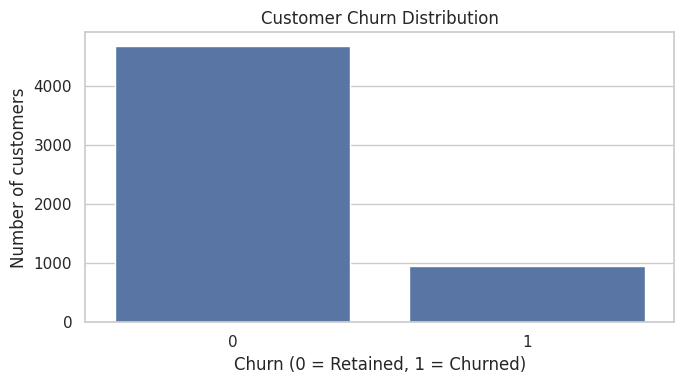

In [5]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

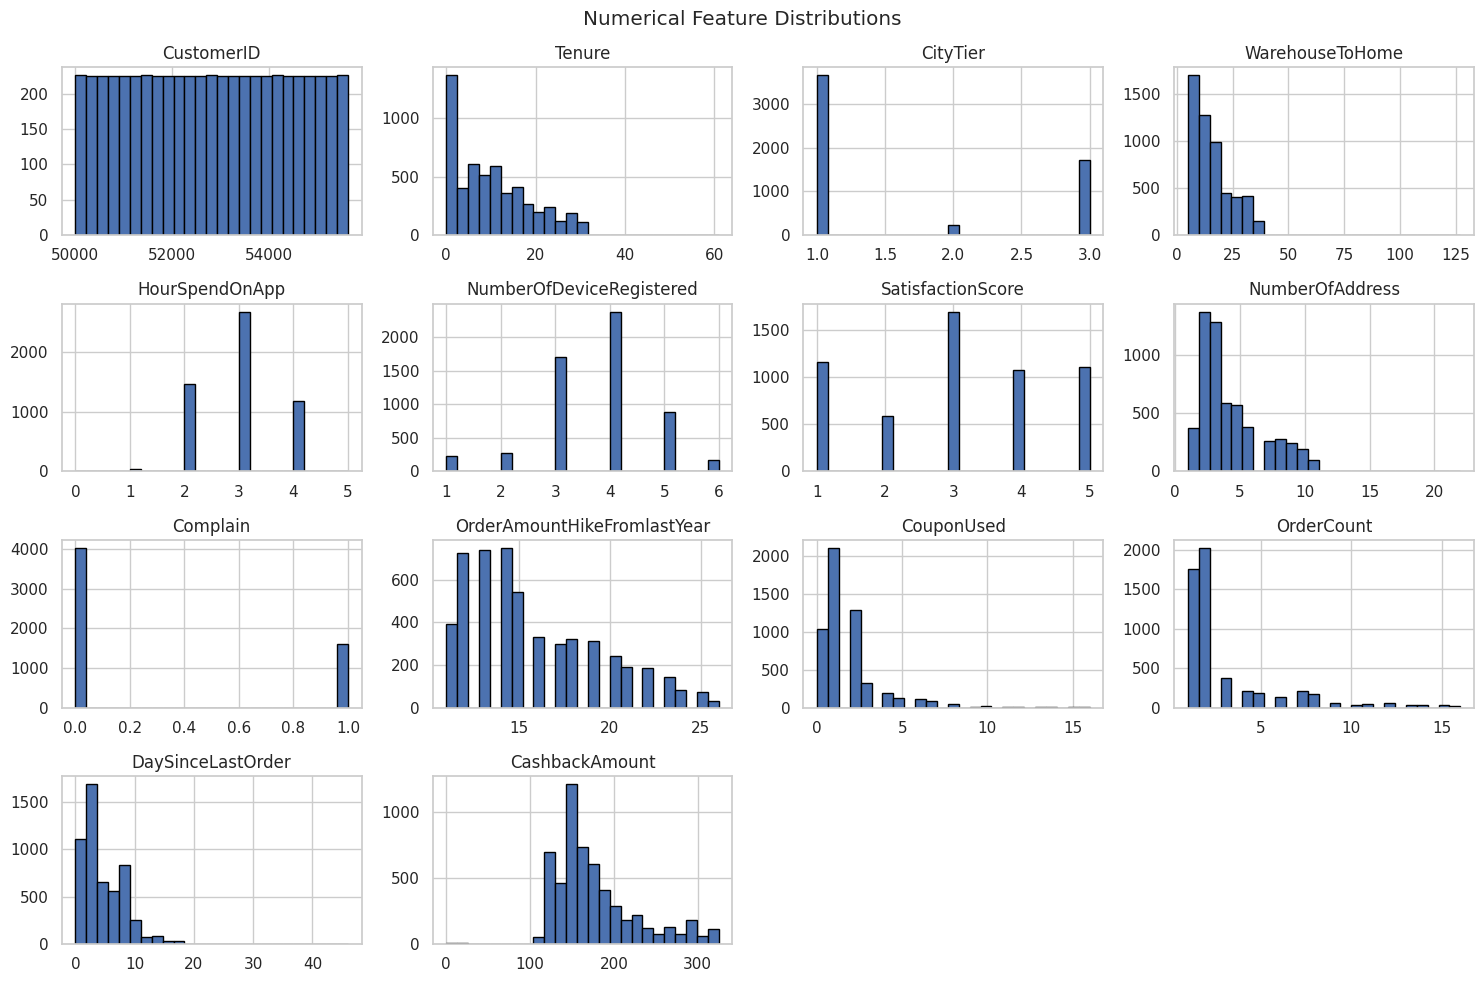

In [6]:
numeric_cols_all = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols_all = [c for c in numeric_cols_all if c != "Churn"]

if numeric_cols_all:
    df[numeric_cols_all].hist(figsize=(15, 10), bins=25, edgecolor="black")
    plt.suptitle("Numerical Feature Distributions")
    plt.tight_layout()
    plt.show()

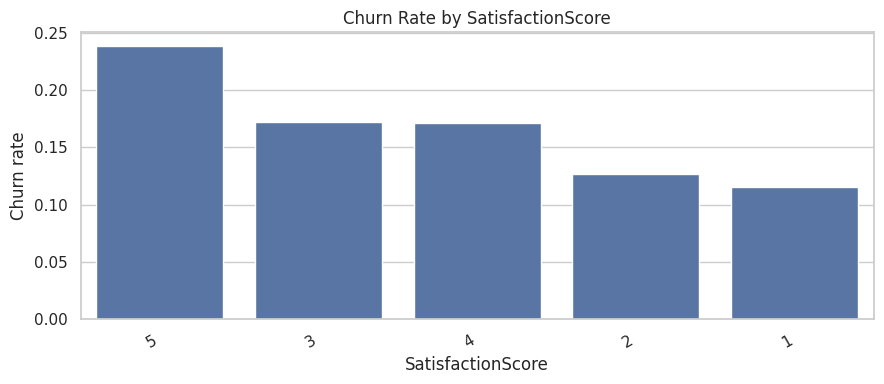

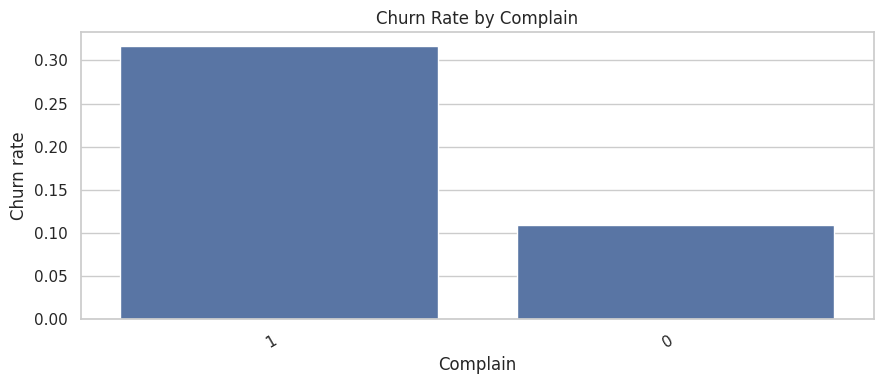

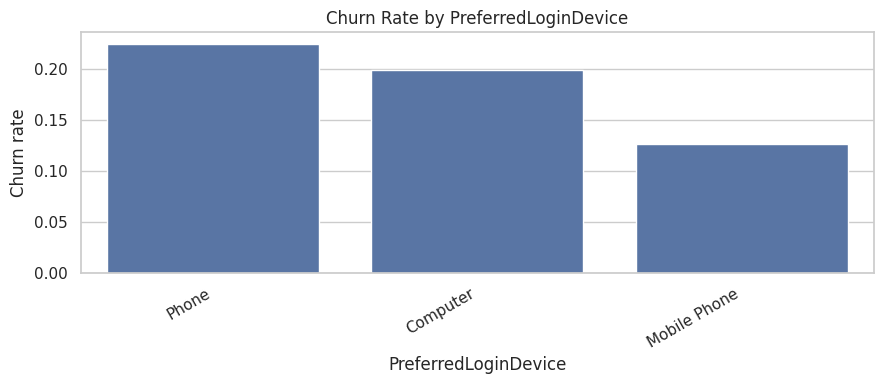

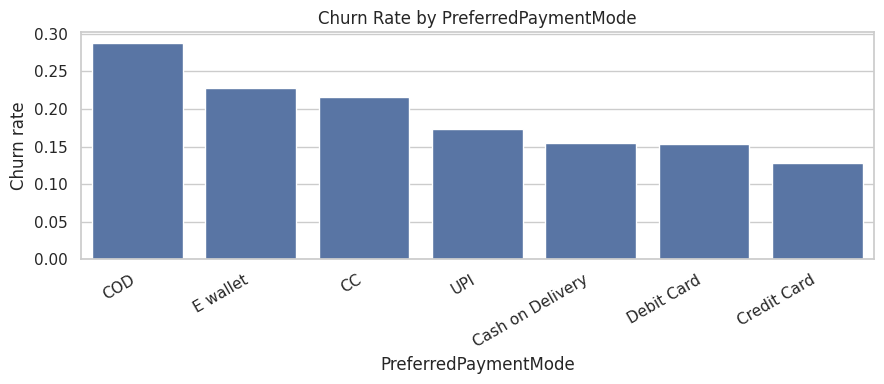

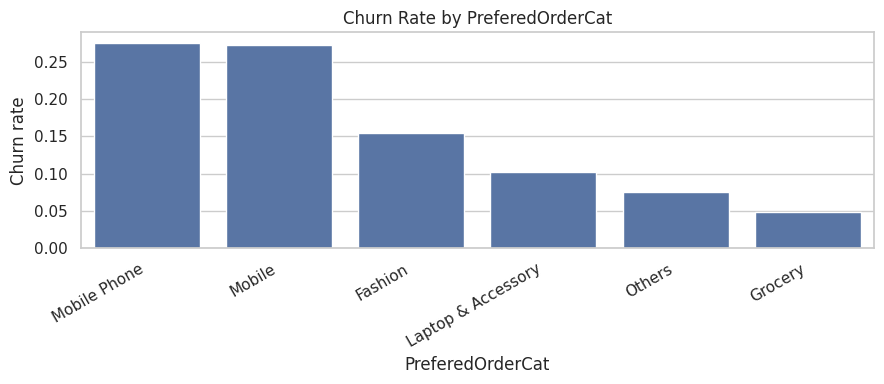

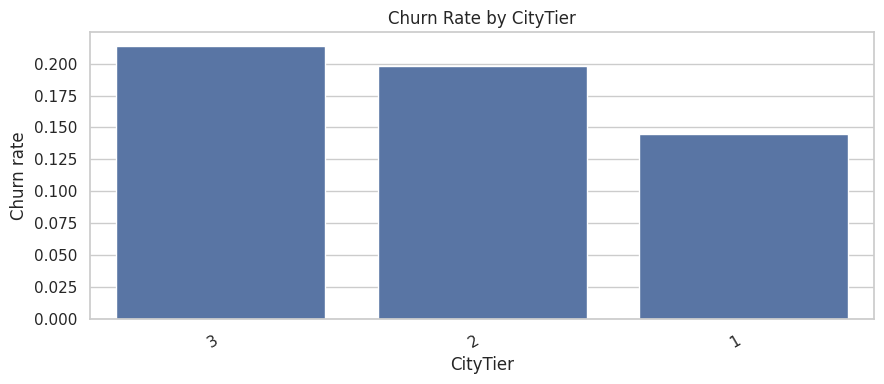

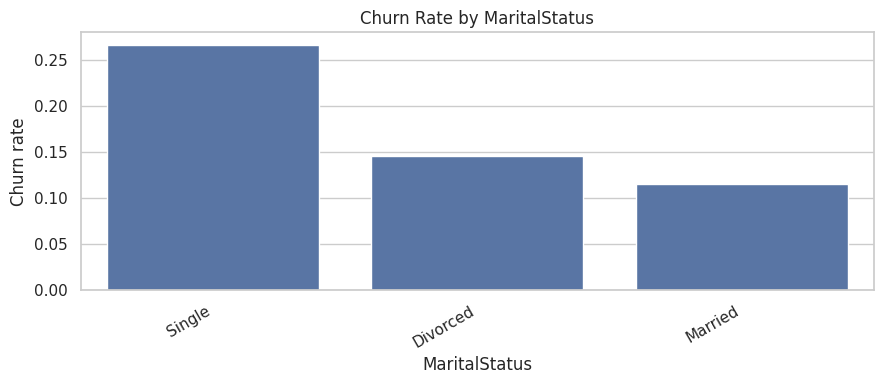

In [7]:
candidate_features = [
    "SatisfactionScore", "Complain", "Tenure", "PreferredLoginDevice",
    "PreferredPaymentMode", "PreferedOrderCat", "CityTier", "MaritalStatus"
]
available_features = [c for c in candidate_features if c in df.columns]

for col in available_features:
    if df[col].nunique(dropna=True) <= 15:
        rates = df.groupby(col, dropna=False)["Churn"].mean().sort_values(ascending=False)
        plt.figure(figsize=(9, 4))
        sns.barplot(x=rates.index.astype(str), y=rates.values)
        plt.title(f"Churn Rate by {col}")
        plt.ylabel("Churn rate")
        plt.xlabel(col)
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

In [8]:
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Remove identifiers that generally do not provide useful generalizable signal.
id_columns = [
    c for c in X.columns
    if c.strip().lower() in {"customerid", "customer_id", "customer id", "rownumber"}
]
X = X.drop(columns=id_columns, errors="ignore")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Removed ID columns:", id_columns)
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature matrix shape:", X.shape)

Removed ID columns: ['CustomerID']
Numerical features: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical features: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
Feature matrix shape: (5630, 18)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 4504
Testing rows: 1126


In [10]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [11]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
results = pd.DataFrame({"Metric": list(metrics.keys()), "Score": list(metrics.values())})
display(results.style.format({"Score":"{:.4f}"}))

print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["Retained", "Churned"], zero_division=0
))

,Metric,Score
0,Accuracy,0.9654
1,Precision,0.9037
2,Recall,0.8895
3,F1-score,0.8966
4,ROC-AUC,0.9926


              precision    recall  f1-score   support

    Retained       0.98      0.98      0.98       936
     Churned       0.90      0.89      0.90       190

    accuracy                           0.97      1126
   macro avg       0.94      0.94      0.94      1126
weighted avg       0.97      0.97      0.97      1126



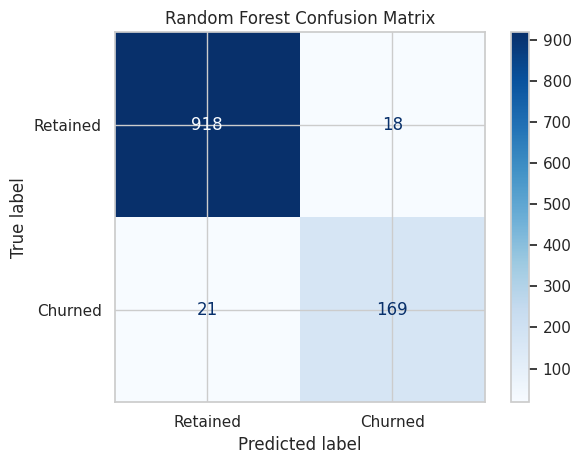

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Retained", "Churned"],
    cmap="Blues", values_format="d"
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

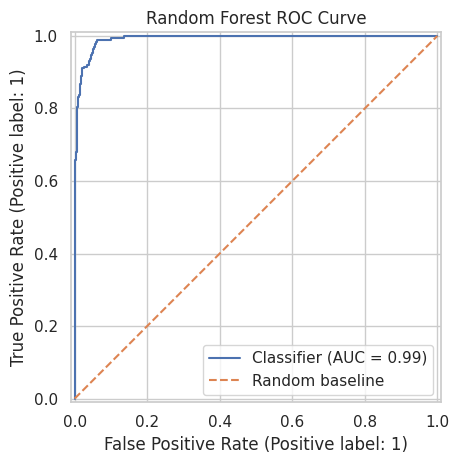

In [13]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Importance
0,num__Tenure,0.249505
12,num__CashbackAmount,0.095259
7,num__Complain,0.068988
11,num__DaySinceLastOrder,0.060184
2,num__WarehouseToHome,0.057077
6,num__NumberOfAddress,0.049956
8,num__OrderAmountHikeFromlastYear,0.046665
5,num__SatisfactionScore,0.044640
4,num__NumberOfDeviceRegistered,0.029196
10,num__OrderCount,0.027807


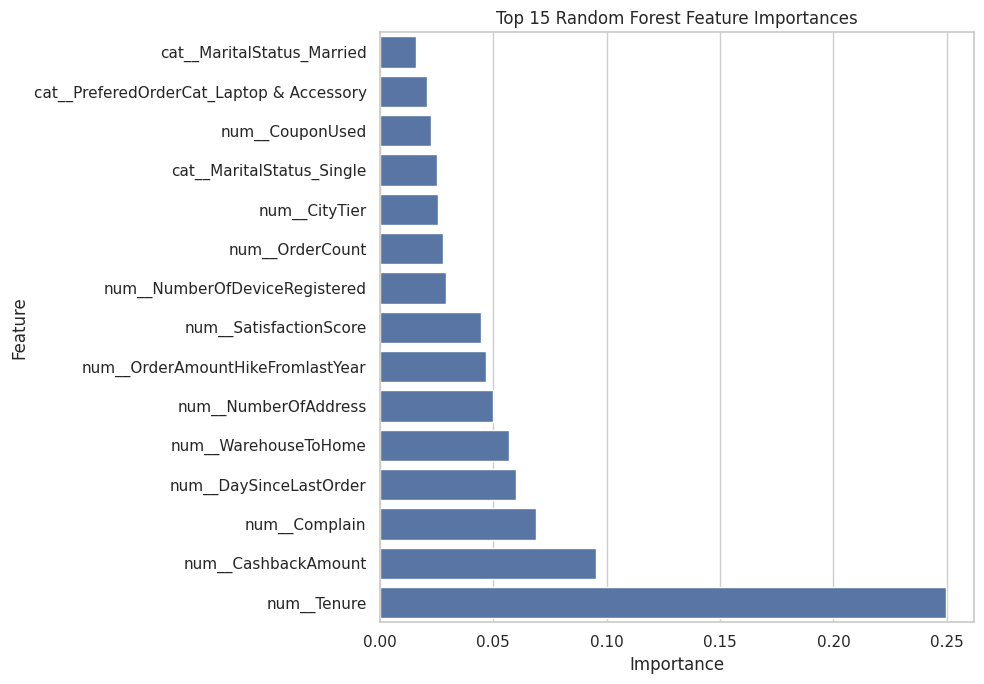

In [14]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances = rf_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")
plt.figure(figsize=(10, 7))
sns.barplot(data=top_features, x="Importance", y="Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

In [15]:
risk_results = X_test.copy()
risk_results["Actual_Churn"] = y_test
risk_results["Predicted_Churn"] = y_pred
risk_results["Churn_Probability"] = y_prob
risk_results["Risk_Level"] = pd.cut(
    risk_results["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)
risk_results = risk_results.sort_values("Churn_Probability", ascending=False)

display(risk_results.head(20))

,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,...,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
4287,1.0,Phone,3,29.0,E wallet,Male,3.0,4,Mobile Phone,3,...,1,20.0,2.0,2.0,1.0,141.75,1,1,0.972387,High
4617,1.0,Computer,3,12.0,E wallet,Male,4.0,4,Mobile Phone,4,...,1,15.0,2.0,2.0,1.0,143.78,1,1,0.966407,High
1011,0.0,Phone,1,NaN,CC,Male,2.0,3,Mobile,4,...,1,17.0,0.0,1.0,0.0,124.08,1,1,0.951919,High
4022,1.0,Computer,1,31.0,Debit Card,Male,4.0,5,Mobile Phone,1,...,1,25.0,2.0,2.0,1.0,149.39,1,1,0.946075,High
338,0.0,Phone,1,NaN,COD,Male,3.0,5,Mobile,2,...,1,18.0,1.0,1.0,0.0,123.40,1,1,0.929599,High
1802,NaN,Computer,3,11.0,E wallet,Male,3.0,3,Mobile Phone,4,...,1,14.0,1.0,1.0,0.0,118.78,1,1,0.924935,High
5433,1.0,Phone,1,15.0,Credit Card,Female,4.0,4,Mobile Phone,5,...,1,18.0,1.0,2.0,1.0,148.98,1,1,0.914017,High
1214,0.0,Phone,1,NaN,Debit Card,Male,3.0,3,Mobile,4,...,1,23.0,1.0,1.0,0.0,124.72,1,1,0.910251,High
3750,1.0,Computer,1,16.0,Credit Card,Male,3.0,4,Mobile Phone,5,...,1,12.0,1.0,2.0,1.0,156.72,1,1,0.909270,High
5346,1.0,Computer,3,19.0,UPI,Male,3.0,4,Laptop & Accessory,1,...,1,25.0,6.0,7.0,8.0,170.81,1,1,0.908671,High


In [16]:
os.makedirs("outputs", exist_ok=True)

joblib.dump(rf_model, "outputs/random_forest_churn_model.joblib")
results.to_csv("outputs/model_evaluation_results.csv", index=False)
importance_df.to_csv("outputs/feature_importance.csv", index=False)
risk_results.to_csv("outputs/customer_churn_predictions.csv", index=False)

print("Saved files:")
print("- outputs/random_forest_churn_model.joblib")
print("- outputs/model_evaluation_results.csv")
print("- outputs/feature_importance.csv")
print("- outputs/customer_churn_predictions.csv")

Saved files:
- outputs/random_forest_churn_model.joblib
- outputs/model_evaluation_results.csv
- outputs/feature_importance.csv
- outputs/customer_churn_predictions.csv
